# **Image color space**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, data, img_as_ubyte, img_as_float
from skimage.color import rgb2hsv, rgb2lab, hsv2rgb
from skimage.transform import rotate
from skimage.exposure import equalize_hist

**1 RGB color image**

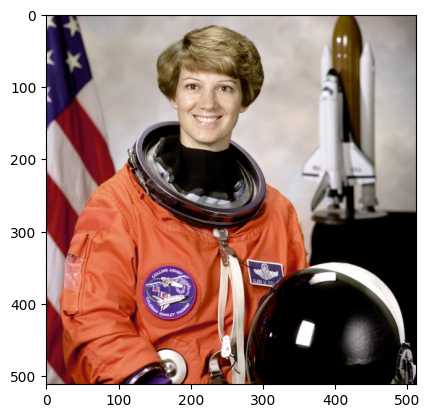

In [5]:
im = data.astronaut()

plt.imshow(im)
plt.show()

**2 Isolate single color channel**

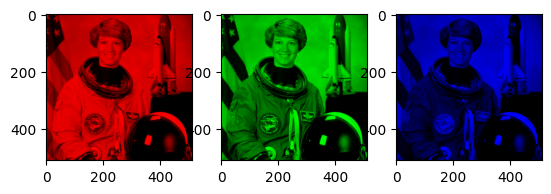

In [6]:
def rgb_isolate_channel(im, ch):
 imc = im.copy()
 for c in range(im.shape[2]):
  if c != ch:
   imc[:,:,c] = np.zeros_like(im[:,:,c])
 return imc

im = data.astronaut()
imr = rgb_isolate_channel(im, 0)
img = rgb_isolate_channel(im, 1)
imb = rgb_isolate_channel(im, 2)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(imr)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(img)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imb)

**3 Isolate single channel**

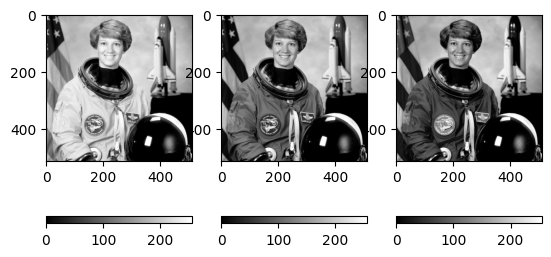

In [7]:
im = data.astronaut()
imr = im[:,:,0]
img = im[:,:,1]
imb = im[:,:,2]

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(imr, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(img, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imb, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**4 RGB 2 HSV**

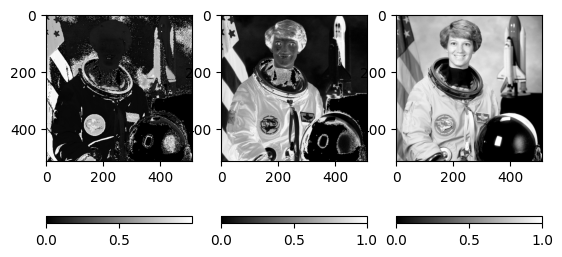

In [8]:
im = data.astronaut()
im_hsv = rgb2hsv(im)
im_hsv_h = im_hsv[:,:,0]
im_hsv_s = im_hsv[:,:,1]
im_hsv_v = im_hsv[:,:,2]

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im_hsv_h, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im_hsv_s, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(im_hsv_v, cmap='gray')
c = plt.colorbar(orientation='horizontal')

**5 RGB 2 CIE LAB**

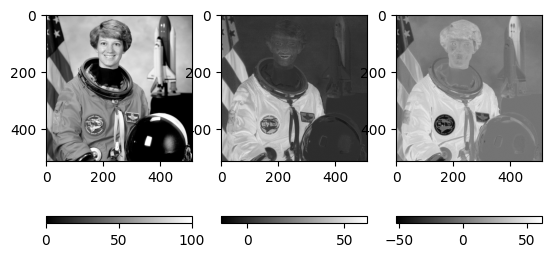

In [9]:
im = data.astronaut()
im_lab = rgb2lab(im)
im_lab_l = im_lab[:,:,0]
im_lab_a = im_lab[:,:,1]
im_lab_b = im_lab[:,:,2]

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im_lab_l, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im_lab_a, cmap='gray')
c = plt.colorbar(orientation='horizontal')

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(im_lab_b, cmap='gray')
c = plt.colorbar(orientation='horizontal')

**6 Color mapping**

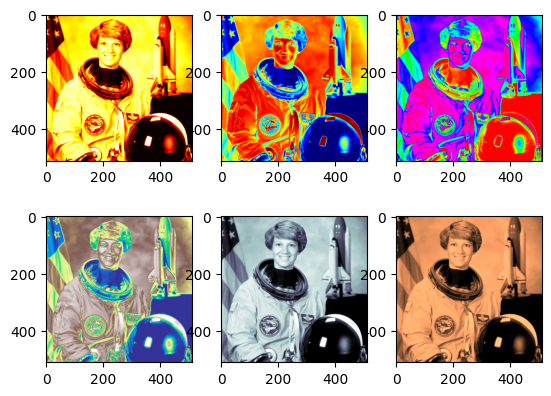

In [10]:
im = data.astronaut()
im_gray = im[:,:,0]

cm = plt.get_cmap('hot')
im_idx1 = cm(im_gray)

cm = plt.get_cmap('jet')
im_idx2 = cm(im_gray)

cm = plt.get_cmap('hsv')
im_idx3 = cm(im_gray)

cm = plt.get_cmap('terrain')
im_idx4 = cm(im_gray)

cm = plt.get_cmap('bone')
im_idx5 = cm(im_gray)

cm = plt.get_cmap('copper')
im_idx6 = cm(im_gray)

fig = plt.figure()
ax = fig.add_subplot(2, 3, 1)
plt.imshow(im_idx1)
ax = fig.add_subplot(2, 3, 2)
plt.imshow(im_idx2)
ax = fig.add_subplot(2, 3, 3)
plt.imshow(im_idx3)
ax = fig.add_subplot(2, 3, 4)
plt.imshow(im_idx4)
ax = fig.add_subplot(2, 3, 5)
plt.imshow(im_idx5)
ax = fig.add_subplot(2, 3, 6)
plt.imshow(im_idx6)
plt.show()

**7 RGB histogram**

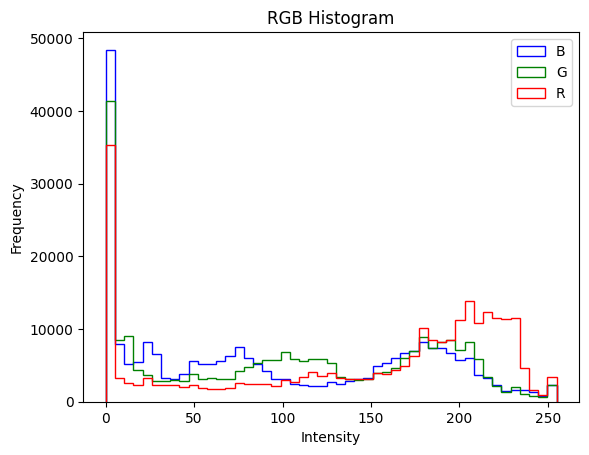

In [11]:
im = data.astronaut()
r = np.concatenate(im[:,:,0])
g = np.concatenate(im[:,:,1])
b = np.concatenate(im[:,:,2])
bins = np.linspace(0, 255, 50)

plt.hist([r, g, b], bins, label=['R', 'G', 'B'], color=['r', 'g', 'b'], histtype='step')
plt.legend(loc='upper right')
plt.title("RGB Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

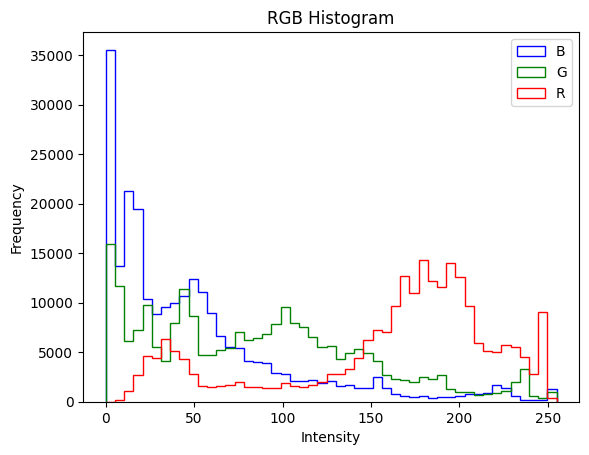

In [12]:
im = data.coffee()
r = np.concatenate(im[:,:,0])
g = np.concatenate(im[:,:,1])
b = np.concatenate(im[:,:,2])
bins = np.linspace(0, 255, 50)

plt.hist([r, g, b], bins, label=['R', 'G', 'B'], color=['r', 'g', 'b'], histtype='step')
plt.legend(loc='upper right')
plt.title("RGB Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

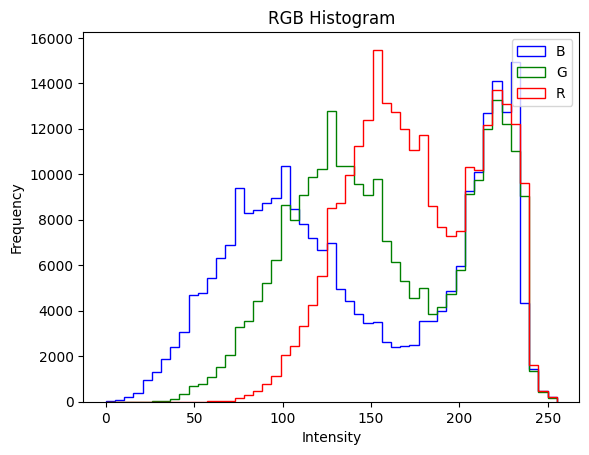

In [13]:
im = data.immunohistochemistry()
r = np.concatenate(im[:,:,0])
g = np.concatenate(im[:,:,1])
b = np.concatenate(im[:,:,2])
bins = np.linspace(0, 255, 50)

plt.hist([r, g, b], bins, label=['R', 'G', 'B'], color=['r', 'g', 'b'], histtype='step')
plt.legend(loc='upper right')
plt.title("RGB Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

**8 Histograms intersection**

[np.float64(0.7070833333333333), np.float64(0.6496391296386719), np.float64(0.8468704223632812)]


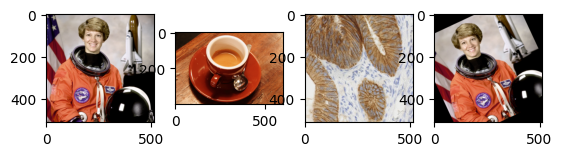

In [15]:
im1 = data.astronaut()
im2 = data.coffee()
im3 = data.immunohistochemistry()
im4 = rotate(im1,25)

fig = plt.figure()
ax = fig.add_subplot(1, 4, 1)
p = plt.imshow(im1)
ax = fig.add_subplot(1, 4, 2)
p = plt.imshow(im2)
ax = fig.add_subplot(1, 4, 3)
p = plt.imshow(im3)
ax = fig.add_subplot(1, 4, 4)
p = plt.imshow(im4)

im1 = np.concatenate(im1[:,:,0])
im2 = np.concatenate(im2[:,:,0])
im3 = np.concatenate(im3[:,:,0])
im4 = np.concatenate(im4[:,:,0])

hist_1, _ = np.histogram(im1, bins=100)
hist_2, _ = np.histogram(im2, bins=100)
hist_3, _ = np.histogram(im3, bins=100)
hist_4, _ = np.histogram(im4, bins=100)

intersection_12 = np.true_divide(np.sum(np.minimum(hist_1, hist_2)), np.sum(hist_2))
intersection_13 = np.true_divide(np.sum(np.minimum(hist_1, hist_3)), np.sum(hist_3))
intersection_14 = np.true_divide(np.sum(np.minimum(hist_1, hist_4)), np.sum(hist_4))
print([intersection_12, intersection_13, intersection_14])

**9 Hist equalization**

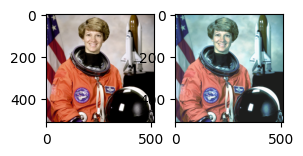

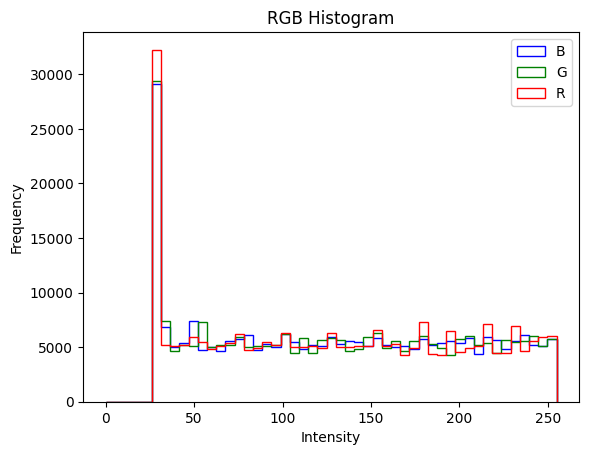

In [16]:
im = data.astronaut()
im_eq = img_as_float(im.copy())
im_eq[:,:,0] = equalize_hist(im[:,:,0])
im_eq[:,:,1] = equalize_hist(im[:,:,1])
im_eq[:,:,2] = equalize_hist(im[:,:,2])
im_eq = img_as_ubyte(im_eq)

fig = plt.figure()
ax = fig.add_subplot(1, 4, 1)
p = plt.imshow(im)
ax = fig.add_subplot(1, 4, 2)
p = plt.imshow(im_eq)

r = np.concatenate(im_eq[:,:,0])
g = np.concatenate(im_eq[:,:,1])
b = np.concatenate(im_eq[:,:,2])
bins = np.linspace(0, 255, 50)

fig = plt.figure()
plt.hist([r, g, b], bins, label=['R', 'G', 'B'], color=['r', 'g', 'b'], histtype='step')
plt.legend(loc='upper right')
plt.title("RGB Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

**10 HVS-based hist equalization**

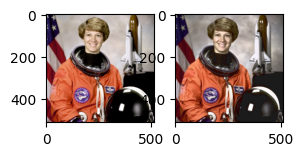

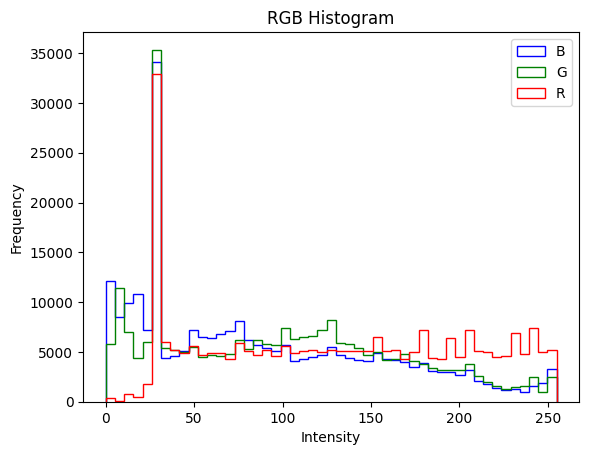

In [17]:
im = data.astronaut()
im_hsv = rgb2hsv(im)
im_hsv_v_eq = equalize_hist(im_hsv[:,:,2]) # V
im_hsv[:,:,2] = im_hsv_v_eq
im_eq = hsv2rgb(im_hsv)
im_eq = img_as_ubyte(im_eq)

fig = plt.figure()
ax = fig.add_subplot(1, 4, 1)
p = plt.imshow(im)
ax = fig.add_subplot(1, 4, 2)
p = plt.imshow(im_eq)

r = np.concatenate(im_eq[:,:,0])
g = np.concatenate(im_eq[:,:,1])
b = np.concatenate(im_eq[:,:,2])
bins = np.linspace(0, 255, 50)

fig = plt.figure()
plt.hist([r, g, b], bins, label=['R', 'G', 'B'], color=['r', 'g', 'b'], histtype='step')
plt.legend(loc='upper right')
plt.title("RGB Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()